# 1. Objective 

## Greek Letter calculation

Implement and compare analytical and numerical approaches for computing Delta and Vega of European put options under Black–Scholes–Merton model.

# 2. Preliminary

## 2.1 Theoretical result

Take European put option with continuous dividend yield for example. We know the Black-Scholes-Merton formula for the put option:

$$
V=Ke^{-rT}N(-d_-)-S_0e^{-qT}N(-d_+),
$$

$$
d_\pm=\frac{1}{\sigma \sqrt{T}}\left[ \log\frac{S_0}{K}+(r-q\pm \frac{1}{2}\sigma^2)T\right],
$$

where $N$ is the cumulative distribution function for the standard normal distribution. From the definiton of Greek letters, we derive that 

$$
\Delta=\frac{\partial V}{\partial S_0}=-e^{-qT}N(-d_+),
$$

and 

$$
\mathrm{Vega}=\frac{\partial V}{\partial \sigma}=S_0e^{-qT}\phi(d_+)\sqrt{T}. 
$$

Here $\phi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}$ is the probability density function (PDF) for $X\sim N(0,1)$.

## 2.2 Strategy

We use above BS Greek formula as benchmark and compare Greeks letter in two aspects:

- 1. bump and reprice.

$$
\Delta \approx \frac{c(S_0+h)-c(S_0-h)}{2h},\qquad 
\mathrm{Vega}\approx \frac{c(\sigma+h)-c(\sigma-h)}{2h}. 
$$

- 2. PDE solver via finite difference. We use finite difference method to formulate the PDE solver to calculate Greeks letter.

# 3. Experiment Design

Consider a $5$-month European put option on a dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, the continuous dividend yield is $0.3\%$ and the volatility is $40\%$ per annum. This means that $S_0=50,K=50,r=0.1,q=0.003,\sigma=0.4,T=5/12$.

# 4. Numerical Implementation

In [4]:
import sys
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
SRC_DIR=PROJECT_ROOT/'src'

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0,str(SRC_DIR))

print(str(SRC_DIR) in sys.path)

True


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The analytic value for The Greek letter is:
 Delta=-0.3871, Vega=12.3457.

Take h in [10, 8, 5, 3, 1, 0.5, 0.1, 0.05, 0.01, 0.005] respectively, 
the central difference value delta=[-0.4058 -0.3995 -0.3922 -0.3889 -0.3873 -0.3871 -0.3871 -0.3871 -0.3871
 -0.3871].
Take h in [0.1, 0.05, 0.02, 0.01, 0.005] respectively, 
the central difference value vega=[12.3335 12.3428 12.3452 12.3456 12.3457]


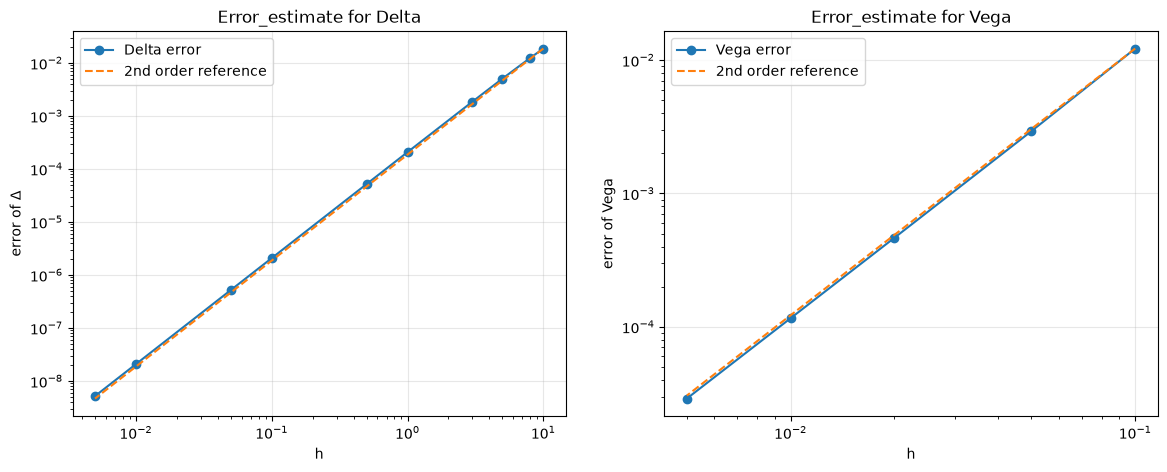

Estimate slope=1.9909 for delta.
Estimate slope=2.0152 for vega.


In [7]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

import black_scholes as bs
import pde_solver as fd 
import greeks as gk

# Set parameters
S0=50;K=50;T=5/12;r=0.1;q=0.003;sigma=0.4

# Bump and reprice 
h_interval=[10,8,5,3,1,0.5,0.1,0.05,0.01,0.005]
h_vega=[0.1,0.05,0.02,0.01,0.005]

delta_bs,vega_bs=gk.bs_greeks(S0,K,T,r,q,sigma,option_type='put')

delta_center=[]
vega_center=[]

for h in h_interval:
    delta_h=(
        bs.bs_calculator(S0+h,K,T,r,q,sigma,option_type='put')-bs.bs_calculator(S0-h,K,T,r,q,sigma,option_type='put')
    )/(2*h)
    delta_center.append(delta_h)
for h1 in h_vega:
    vega_h1=(
        bs.bs_calculator(S0,K,T,r,q,sigma+h1,option_type='put')-bs.bs_calculator(S0,K,T,r,q,sigma-h1,option_type='put')
    )/(2*h1)
    vega_center.append(vega_h1)


print(f'The analytic value for The Greek letter is:\n Delta={delta_bs:.4f}, Vega={vega_bs:.4f}.')
print()
print(f'Take h in {h_interval} respectively, \nthe central difference value delta={np.round(np.array(delta_center),4)}.')
print(f'Take h in {h_vega} respectively, \nthe central difference value vega={np.round(np.array(vega_center),4)}')

# Plot error estimation
h_interval=np.array(h_interval)
h_vega=np.array(h_vega)
error_delta=np.abs(delta_center-delta_bs)
error_vega=np.abs(vega_center-vega_bs)
ref1=(h_interval/h_interval[0])**2
ref2=(h_vega/h_vega[0])**2

fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].loglog(h_interval,error_delta,marker='o',label='Delta error')
ax[0].loglog(h_interval,error_delta[0]*ref1,'--',label='2nd order reference')
ax[0].set_title('Error_estimate for Delta')
ax[0].set_xlabel('h')
ax[0].set_ylabel(r'error of $\Delta$')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].loglog(h_vega,error_vega,marker='o',label='Vega error')
ax[1].loglog(h_vega,error_vega[0]*ref2,'--',label='2nd order reference')
ax[1].set_title('Error_estimate for Vega')
ax[1].set_xlabel('h')
ax[1].set_ylabel(r'error of $\mathrm{Vega}$')
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'03_greeks_bump_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

#Convergence rate estimate
slope,intercept=np.polyfit(np.log(h_interval),np.log(error_delta),1)
print(f'Estimate slope={slope:.4f} for delta.')

slope2,intercept2=np.polyfit(np.log(h_vega),np.log(error_vega),1)
print(f'Estimate slope={slope2:.4f} for vega.')


Spatial convergence, fix N=1600
The exact Greeks using BS formula are Delta=-0.38709562, Vega=12.34569149.
Delta from Crank Nicolson solver are [-0.38725131 -0.38713452 -0.38710537 -0.38709809].
Vega from Crank Nicolson solver are [12.35575214 12.34819506 12.34631142 12.34584086].


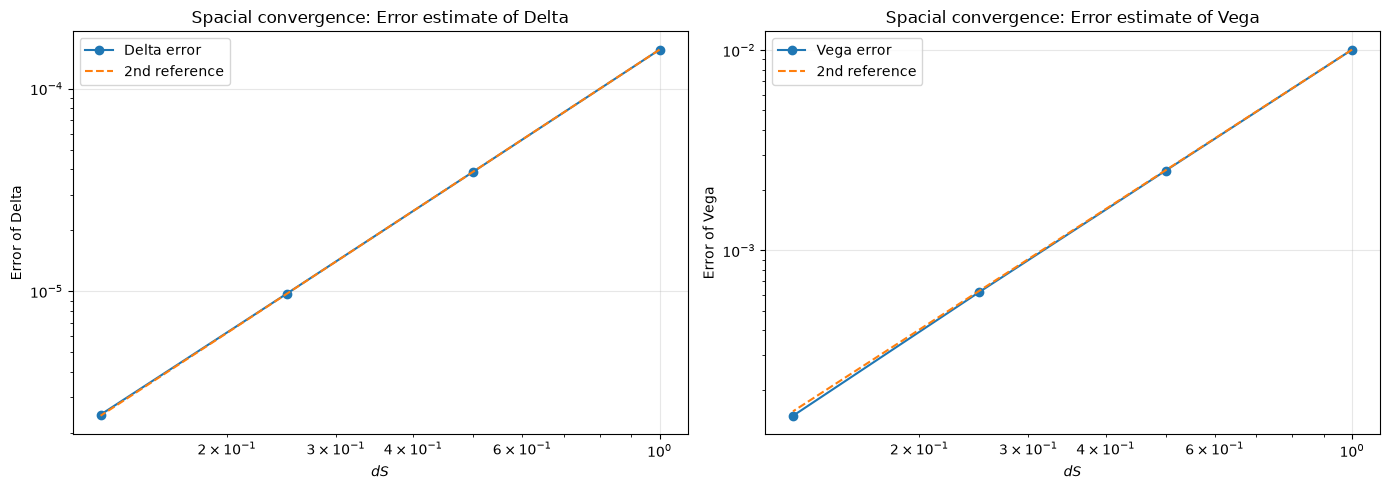

Estimate slope=1.9945 for delta.
Estimate slope=2.0235 for Vega.

Temporal convergence, fix M=800
The exact Greeks using BS formula are Delta=-0.38709562, Vega=12.34569149.
Delta from Crank Nicolson solver are [-0.38706736 -0.38709754 -0.38709806 -0.38709808 -0.38709809].
Vega from Crank Nicolson solver are [12.32243541 12.34570884 12.34584332 12.34584136 12.34584086].


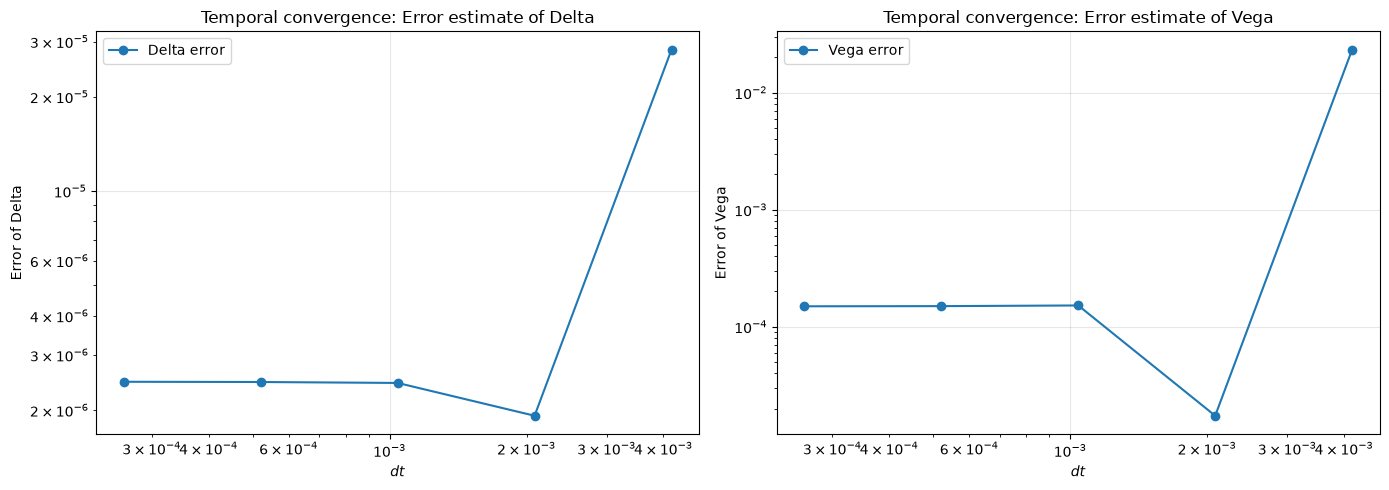

In [9]:
# Theoretical Value of Delta and Vega
put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')
delta_bs,vega_bs=gk.bs_greeks(S0,K,T,r,q,sigma,option_type='put')

Smax=100
dSigma=0.001


# Experiment A-----Spatical convergence
N=1600
M_interval=[100,200,400,800]

delta_spatial=[]
vega_spatial=[]
for M in M_interval:
    temp_S,temp_call=fd.bs_put_CrankNicolson_stab(S0,K,T,r,q,sigma,M,N,Smax)
    dS=Smax/M
    idx=np.argmin(np.abs(temp_S-S0))
    temp_delta=(temp_call[idx+1]-temp_call[idx-1])/(2*dS)
    delta_spatial.append(temp_delta)

    temp_vega=(
        fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma+dSigma,M,N,Smax)-fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma-dSigma,M,N,Smax)
    )/(2*dSigma)
    vega_spatial.append(temp_vega)

delta_spatial=np.array(delta_spatial)
vega_spatial=np.array(vega_spatial)

print(f'\nSpatial convergence, fix N={N}')
print(f'The exact Greeks using BS formula are Delta={delta_bs:.8f}, Vega={vega_bs:.8f}.')
print(f'Delta from Crank Nicolson solver are {np.round(delta_spatial,8)}.')
print(f'Vega from Crank Nicolson solver are {np.round(vega_spatial,8)}.')

#Plot error of Delta and Vega
dS=np.array([Smax/M for M in M_interval])
error_delta_spatial=np.abs(delta_spatial-delta_bs)
error_vega_spatial=np.abs(vega_spatial-vega_bs)
ref=(dS/dS[0])**2

fig,axes=plt.subplots(1,2,figsize=(14,5))

axes[0].loglog(dS,error_delta_spatial,marker='o',label='Delta error')
axes[0].loglog(dS,error_delta_spatial[0]*ref,'--',label='2nd reference')
axes[0].set_xlabel(r'$dS$')
axes[0].set_ylabel(r'Error of Delta')
axes[0].set_title(r'Spacial convergence: Error estimate of Delta')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].loglog(dS,error_vega_spatial,marker='o',label='Vega error')
axes[1].loglog(dS,error_vega_spatial[0]*ref,'--',label='2nd reference')
axes[1].set_xlabel(r'$dS$')
axes[1].set_ylabel(r'Error of Vega')
axes[1].set_title(r'Spacial convergence: Error estimate of Vega')
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()

plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'03_greeks_pde_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

slop3,intercept3=np.polyfit(np.log(dS),np.log(error_delta_spatial),1)
slop4,intercept4=np.polyfit(np.log(dS),np.log(error_vega_spatial),1)

print(f'Estimate slope={slop3:.4f} for delta.')
print(f'Estimate slope={slop4:.4f} for Vega.')


# Experiment B-----Temporal convergence
M=800
N_interval=[100,200,400,800,1600]

delta_temporal=[]
vega_temporal=[]
for N in N_interval:
    temp_S,temp_call=fd.bs_put_CrankNicolson_stab(S0,K,T,r,q,sigma,M,N,Smax)
    dS=Smax/M
    idx=np.argmin(np.abs(temp_S-S0))
    temp_delta=(temp_call[idx+1]-temp_call[idx-1])/(2*dS)
    delta_temporal.append(temp_delta)

    temp_vega=(
        fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma+dSigma,M,N,Smax)-fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma-dSigma,M,N,Smax)
    )/(2*dSigma)
    vega_temporal.append(temp_vega)

delta_temporal=np.array(delta_temporal)
vega_temporal=np.array(vega_temporal)

print(f'\nTemporal convergence, fix M={M}')
print(f'The exact Greeks using BS formula are Delta={delta_bs:.8f}, Vega={vega_bs:.8f}.')
print(f'Delta from Crank Nicolson solver are {np.round(delta_temporal,8)}.')
print(f'Vega from Crank Nicolson solver are {np.round(vega_temporal,8)}.')

#Plot error of Delta and Vega
dt=np.array([T/N for N in N_interval])
error_delta_temporal=np.abs(delta_temporal-delta_bs)
error_vega_temporal=np.abs(vega_temporal-vega_bs)


fig,axes=plt.subplots(1,2,figsize=(14,5))

axes[0].loglog(dt,error_delta_temporal,marker='o',label='Delta error')

axes[0].set_xlabel(r'$dt$')
axes[0].set_ylabel(r'Error of Delta')
axes[0].set_title(r'Temporal convergence: Error estimate of Delta')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].loglog(dt,error_vega_temporal,marker='o',label='Vega error')

axes[1].set_xlabel(r'$dt$')
axes[1].set_ylabel(r'Error of Vega')
axes[1].set_title(r'Temporal convergence: Error estimate of Vega')
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()

plt.show()


# 5. Results and Analysis

In the bump and reprice experiment, we apply central difference method based on Black Scholes formula. The absolute error both show second order convergence for Delta and Vega, and the slope for the loglog plotting are 1.9909 and 2.0152 respectively. This fits well with the theoretical formula expression. 

The second experiment is to recover Greek letter from Crank Nicolson method. Fix time interval N=1600, the spatial test show second order convergence for Delta and Vega. While fix spatial interval M=800, the temporal test shows that the absolute errors of Delta and Vega converge to a fixed constant. This is because error sourced from fixed spatial interval can not be erased by finer temporal slice. Vega is computed using a central difference with respect to volatility applied to the numerical PDE prices. Therefore, its error contains both PDE discretization error and numerical differentiation error.


# 6. Conclusion

In the experiment, we used Greeks letter from Black Scholes formula as benchmark to test the validity of two approximation methods: bump and reprice and Crank Nicolson finite difference. 

For the bump-and-reprice method, central finite differences were applied to the analytical option pricing formula. The numerical experiments demonstrated approximately second-order convergence for both Delta and Vega, consistent with the theoretical truncation error of \(O(h^2)\).

For the Crank Nicolson approach, when fix temporal interval, the numerical errors in Delta and Vega exhibited approximately second-order convergence. For the temporal convergence experiment, we observed that decreasing the time step while keeping the spatial grid fixed does not eliminate the underlying spatial discretization error. The numerical errors eventually approach a nonzero level. These experiments illustrate the importance of distinguishing numerical differentiation errors from PDE discretization errors when computing option Greeks.